### 05 PCA (exploratory analysis)

Explores the structure of the 24 window features with principal component analysis, to check whether the activities the models found hardest (stairs and shuffling) overlap with other activities in feature space.

**Input:** `data/processed/harth_windows.csv` (from `02_preprocessing.ipynb`)
**Output:** explained variance, loadings and plots only. The data is not changed, and PCA is not used in the models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA

In [2]:
print(Path.cwd())
# Create data directory 
data_directory = Path("../data/processed")
print(list(data_directory.iterdir()))

C:\Users\sarab\Projects\CT4101 ML Project\Machine_Learning_Portfolio_Project\notebooks
[WindowsPath('../data/processed/harth_windows.csv')]


In [3]:
# Read harth_windows csv file
harth_windows = pd.read_csv(data_directory/"harth_windows.csv")
harth_windows.head()

,back_x_mean,back_y_mean,back_z_mean,thigh_x_mean,thigh_y_mean,thigh_z_mean,back_mag_mean,thigh_mag_mean,back_x_sd,back_y_sd,...,back_x_range,back_y_range,back_z_range,thigh_x_range,thigh_y_range,thigh_z_range,back_mag_range,thigh_mag_range,activity,subject
0,-0.985535,0.076321,0.071897,-0.951721,0.066909,-0.300923,0.991294,1.000641,0.008179,0.015925,...,0.042021,0.106730,0.049085,0.026857,0.087156,0.065944,0.049257,0.030911,walking,S006
1,-0.990118,0.098939,0.052922,-0.970774,0.017955,-0.240916,0.996594,1.000600,0.006710,0.014250,...,0.021219,0.064559,0.039445,0.023676,0.082334,0.048104,0.021273,0.019548,standing,S006
2,-0.985489,0.114645,0.066351,-0.971958,0.013050,-0.227268,0.994405,0.998316,0.003794,0.007793,...,0.019534,0.039422,0.033895,0.007465,0.040694,0.031032,0.019653,0.008874,standing,S006
3,-0.986061,0.112886,0.061172,-0.971738,0.010761,-0.241171,0.994513,1.001399,0.004785,0.013871,...,0.021073,0.048442,0.034815,0.035844,0.036097,0.062481,0.023155,0.031511,standing,S006
4,-0.982235,0.143961,0.078188,-0.981988,0.051999,-0.167089,0.996508,1.000266,0.007308,0.028004,...,0.034060,0.127701,0.091557,0.051724,0.117495,0.212539,0.030263,0.033056,standing,S006


In [4]:
# Create a DataFrame with training data
TRAINING = ["S006", "S008", "S009", "S010", "S012", "S013", "S014", "S015", "S016", "S017", "S020", "S021", "S023", "S024", "S026", "S027", "S028", "S029"]

harth_windows_training = harth_windows[harth_windows["subject"].isin(TRAINING)]
harth_windows_training.shape

(96078, 26)

In [5]:
# Separate the inputs and targets
X = harth_windows_training.drop(columns=["activity", "subject"]) # inputs (24 features)
y = harth_windows_training["activity"] # target (activity column)

In [6]:
# Scale features, then do PCA keeping all 24 features
pca_pipeline = make_pipeline(StandardScaler(), PCA())
# Fit the pipeline to the training windows and convert each window into component values
X_pca = pca_pipeline.fit_transform(X)
print(X_pca.shape)
# Pull the PCA step out of the pipeline, so its results can be read
pca = pca_pipeline.named_steps["pca"]
print(pca.explained_variance_ratio_.round(3))
print(np.cumsum(pca.explained_variance_ratio_).round(3))

(96078, 24)
[0.702 0.063 0.057 0.046 0.033 0.03  0.02  0.014 0.007 0.006 0.005 0.004
 0.003 0.002 0.001 0.001 0.001 0.001 0.    0.    0.    0.    0.    0.   ]
[0.702 0.765 0.823 0.869 0.902 0.932 0.952 0.966 0.973 0.979 0.985 0.989
 0.992 0.995 0.996 0.997 0.998 0.998 0.999 0.999 1.    1.    1.    1.   ]


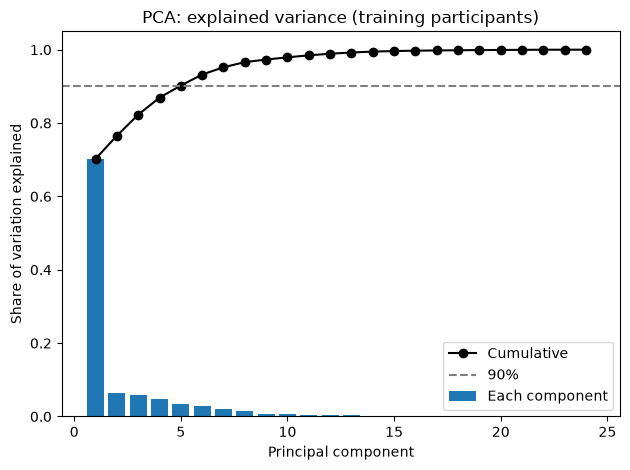

In [7]:
components = np.arange(1, 25)          # component numbers 1 to 24, for the x-axis
ratio = pca.explained_variance_ratio_
cumulative = np.cumsum(ratio)

# Bars: share of variation for each component. Line: running total
plt.bar(components, ratio, label="Each component")
plt.plot(components, cumulative, marker="o", color="black", label="Cumulative")
plt.axhline(0.9, linestyle="--", color="grey", label="90%")

plt.xlabel("Principal component")
plt.ylabel("Share of variation explained")
plt.title("PCA: explained variance (training participants)")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
print(cumulative)

[0.7022061  0.76536405 0.82270276 0.86915522 0.90225067 0.93220682
 0.95202411 0.96602364 0.97307059 0.97914707 0.98453617 0.98899519
 0.99229404 0.99478584 0.99622215 0.99727799 0.99788707 0.99842074
 0.99885997 0.99923359 0.99952139 0.99980622 0.99994593 1.        ]


The first principal component explained about 70.2% of the variance, PC1 + PC2 = 76.5%, and five components explained about 90.2%, showing that the 24 features are highly correlated

# Create 2D plots

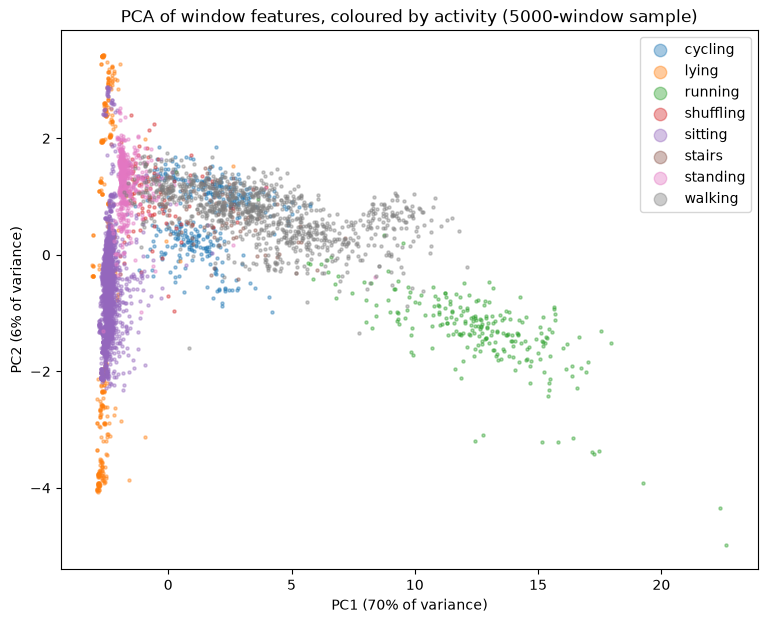

In [9]:
# Create table of PC1, PC2 and activity for every training window
pca_table = pd.DataFrame({"PC1": X_pca[:,0], "PC2": X_pca[:,1], "activity": y.values})
pca_table
# Random sample of 5,000 windows, so the plot is readable
pca_sample = pca_table.sample(5000, random_state=42)
pca_sample

# Plot each activity in its own colour
plt.figure(figsize=(9,7))
for activity, rows in pca_sample.groupby("activity"):
    plt.scatter(rows["PC1"], rows["PC2"], s=5, alpha=0.4, label=activity)

plt.xlabel("PC1 (70% of variance)")
plt.ylabel("PC2 (6% of variance)")
plt.title("PCA of window features, coloured by activity (5000-window sample)")
plt.legend(markerscale=4)
plt.show()

- All PC1 activities appear to be ordered by how much the body moves during the activity. Lying, sitting and standing on the left, followed by cycling, walking and running further right.
- All PC2 activities appear to be ordered by orientation/posture. E.g. for still activites, standing is higher than sitting and lying concentrated at the top and bottom (possibly because of different lying positions which affects sensor orientation)
- Stairs and shuffling are hard to see in the plot but appear to lie inside the walking cloud

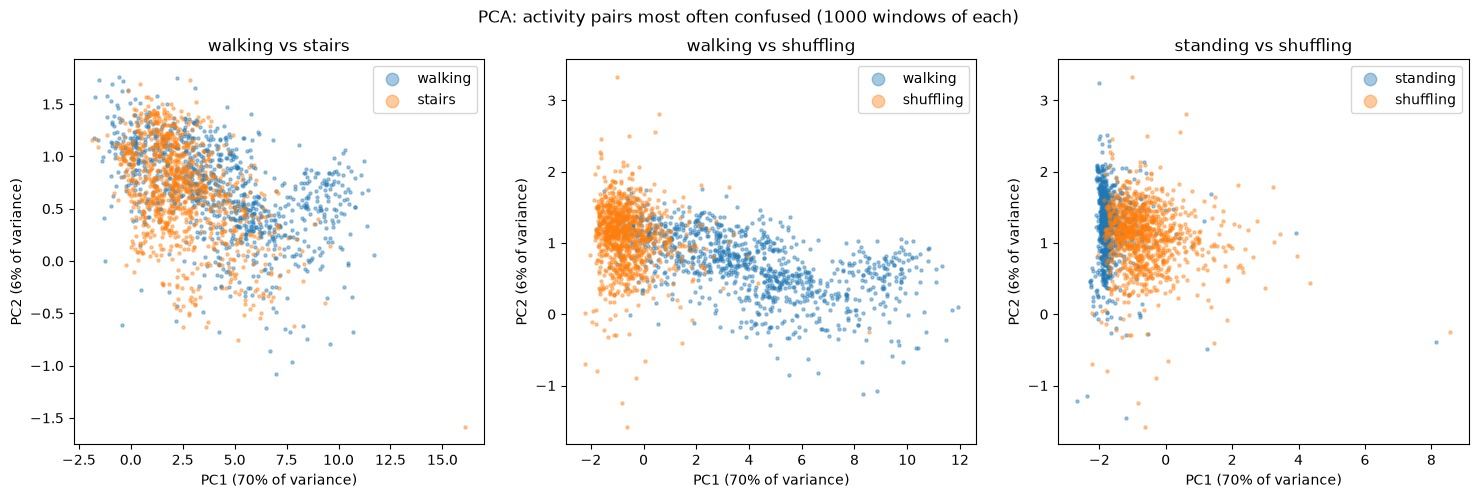

<Figure size 700x500 with 0 Axes>

<Figure size 700x500 with 0 Axes>

<Figure size 700x500 with 0 Axes>

In [10]:
# Compare 2 activityes in PC1-PC2 space, using 1000 radnom windows of each (3 plots in one panel)
def plot_pair(activity_a, activity_b, ax):
    pair = pca_table[pca_table["activity"].isin([activity_a, activity_b])]
    pair_sample = pair.groupby("activity").sample(1000, random_state=42)

    plt.figure(figsize=(7,5))
    for activity in [activity_a, activity_b]: 
        rows = pair_sample[pair_sample["activity"] == activity]
        ax.scatter(rows["PC1"], rows["PC2"], s=5, alpha=0.4, label=activity)

    ax.set_xlabel("PC1 (70% of variance)")
    ax.set_ylabel("PC2 (6% of variance)")
    ax.set_title(f"{activity_a} vs {activity_b}")
    ax.legend(markerscale=4)

fig, axes = plt.subplots(1,3, figsize=(18,5))
plot_pair("walking", "stairs", axes[0])
plot_pair("walking", "shuffling", axes[1])
plot_pair("standing", "shuffling", axes[2])
fig.suptitle("PCA: activity pairs most often confused (1000 windows of each)")
plt.tight_layout()
plt.show()

- Stairs clear sit inside the moderate movement intensity part of the walking cloud, with no clear boundary
- Shuffling lies between standing standing and walking along PC1, with similar posture as standing but with some more movement.

In [11]:
# Loadings: the weight of each original feature in PC1 and PC2.
loadings = pd.DataFrame(pca.components_[:2].T, index=X.columns, columns=["PC1", "PC2"])
print(loadings.sort_values("PC1", key=abs, ascending=False).round(3))
print(loadings.sort_values("PC2", key=abs, ascending=False).round(3))

                   PC1    PC2
thigh_x_sd       0.239 -0.010
back_mag_sd      0.238 -0.069
thigh_x_range    0.234  0.009
back_z_sd        0.234 -0.024
thigh_mag_sd     0.234  0.040
back_mag_range   0.234 -0.087
thigh_y_sd       0.233  0.027
thigh_z_sd       0.232  0.042
back_x_sd        0.231 -0.099
back_y_sd        0.230 -0.022
back_z_range     0.230 -0.046
thigh_mag_mean   0.229 -0.057
thigh_mag_range  0.229  0.041
thigh_z_range    0.229  0.037
back_x_range     0.229 -0.105
back_y_range     0.226 -0.061
thigh_y_range    0.222  0.039
back_mag_mean    0.191 -0.286
thigh_x_mean    -0.173 -0.364
thigh_z_mean    -0.121 -0.432
thigh_y_mean    -0.075 -0.326
back_x_mean     -0.053 -0.175
back_y_mean     -0.029  0.314
back_z_mean     -0.009  0.558
                   PC1    PC2
back_z_mean     -0.009  0.558
thigh_z_mean    -0.121 -0.432
thigh_x_mean    -0.173 -0.364
thigh_y_mean    -0.075 -0.326
back_y_mean     -0.029  0.314
back_mag_mean    0.191 -0.286
back_x_mean     -0.053 -0.175
back_x_ran

- PC1 represents overall movement intensity. All 16 SD and range features carry almost equal weight (0.22-0.24), as well as mean magnitues, which increase with movement. The orientation features (means) have close to 0 weight
- PC2 represents orientation (posture). Mean orientation features carry the most weight (back_z_mean: 0.558, thigh_z_mean: -0.43, thigh_x_mean: 0.36...). The sd and range features have almost 0 weight
Notes:
- The plots only show 76.5 % of the variance, so activities that overlap may still be partly seperable using other components
- This supports the error analysis beca the hard activities lie on a continuum between their neighbours and don't form separate groups, suggesting a limit in the features rather than the models. Features that capture other aspects of movement, such as vertical lift or step frequency may be able to seperate these activities better.
